In [1]:
import numpy as np

class KMeans:

    def __init__(self, n_clusters=3, max_iter=100):
        self.k = n_clusters
        self.max_iter = max_iter

    def fit(self, X):

        # Step 1: Initialize centroids
        random_indices = np.random.choice(
            len(X), self.k, replace=False
        )
        self.centroids = X[random_indices]

        for _ in range(self.max_iter):

            # Step 2: Calculate distances
            distances = np.linalg.norm(
                X[:, np.newaxis] - self.centroids,
                axis=2
            )

            # Step 3: Assign clusters
            self.labels = np.argmin(distances, axis=1)

            # Step 4: Update centroids
            new_centroids = []

            for j in range(self.k):

                cluster_points = X[self.labels == j]

                if len(cluster_points) > 0:
                    new_centroid = np.mean(
                        cluster_points, axis=0
                    )
                else:
                    # Reinitialize an empty cluster
                    new_centroid = X[
                        np.random.choice(len(X))
                    ]

                new_centroids.append(new_centroid)

            new_centroids = np.array(new_centroids)

            # Step 5: Check convergence
            if np.allclose(self.centroids, new_centroids):
                break

            self.centroids = new_centroids

        return self

    def predict(self, X):

        distances = np.linalg.norm(
            X[:, np.newaxis] - self.centroids,
            axis=2
        )

        return np.argmin(distances, axis=1)

    def inertia(self, X):

        distances = np.linalg.norm(
            X - self.centroids[self.labels],
            axis=1
        )

        return np.sum(distances ** 2)

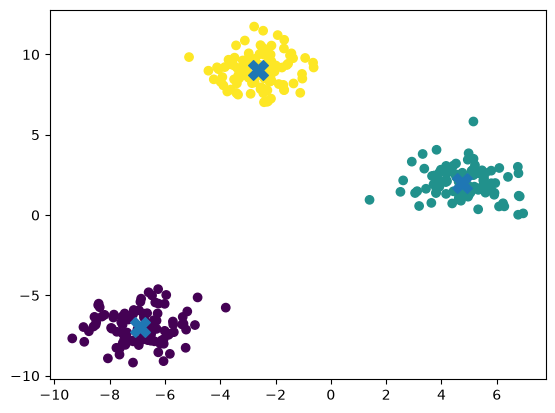

Inertia: 566.8595511244132


In [2]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X, y = make_blobs(
    n_samples=300,
    centers=3,
    random_state=42
)

model = KMeans(n_clusters=3)
model.fit(X)

labels = model.predict(X)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels
)

plt.scatter(
    model.centroids[:, 0],
    model.centroids[:, 1],
    marker='X',
    s=200
)

plt.show()

print("Inertia:", model.inertia(X))

In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model=make_pipeline(StandardScaler(),KMeans(n_clusters=3,init='k-means++',n_init=10,max_iter=100,random_state=42))
model.fit(X)
labels=model.named_steps['kmeans'].labels_